<div align="center">

### Lab 02 | The Physics of EEG

### Cortical Dipoles • Neuronal Synchrony • Signal Formation

**Student ID:** MS26901626 · **Name:** P. K. A. Lakshan

---

**Programming Environment:** Python  
**Libraries:** NumPy • Matplotlib  
**Methodology:** Computational Simulation  

</div>

---

#### Learning Outcomes

By completing this lab, you will be able to:

1.	Simulate neuronal synchrony and quantify how it affects EEG amplitude
2.	Model a simplified dipole potential and quantify the effect of depth (distance)
3.	Model dipole orientation effects and programmatically detect key angles
4.	Simulate multi-dipole interference and relate it to EEG spatial resolution
5.	Produce plots + numeric metrics as evidence

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

np.random.seed(42)
os.makedirs("plots", exist_ok=True)   # added: every required plot is also saved as a PNG for the submission

def rms(x):
    return np.sqrt(np.mean(x**2))

def peak_abs(x):
    return np.max(np.abs(x))

### Part A — Neuronal Synchrony: Simulation + Quantification

#### Step 1 – Generate synchronous vs asynchronous population signals (Run as-is)

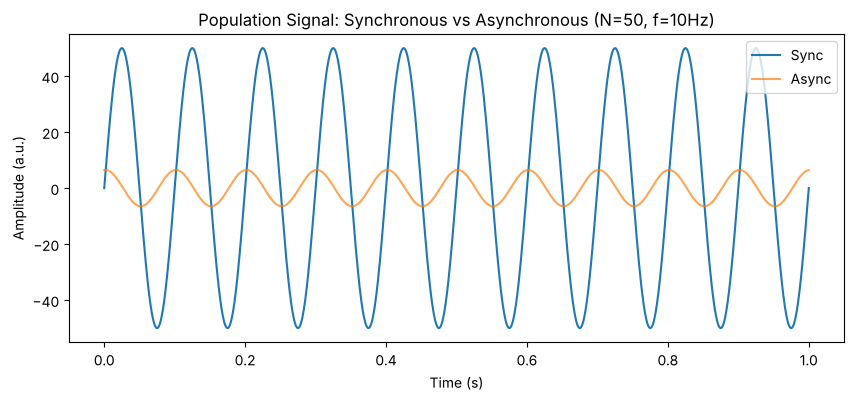

In [2]:
t = np.linspace(0, 1, 1000)   # 1 second
f = 10                        # 10 Hz rhythm
N = 50                        # number of neurons

# Synchronous neurons: same phase
sync_signal = np.sum([np.sin(2*np.pi*f*t) for _ in range(N)], axis=0)

# Asynchronous neurons: random phase
async_signal = np.sum([np.sin(2*np.pi*f*t + np.random.rand()*2*np.pi) for _ in range(N)], axis=0)

plt.figure(figsize=(10,4))
plt.plot(t, sync_signal, label="Sync")
plt.plot(t, async_signal, label="Async", alpha=0.7)
plt.title("Population Signal: Synchronous vs Asynchronous (N=50, f=10Hz)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u.)")
plt.legend()
plt.savefig("plots/1_sync_vs_async.png", dpi=120, bbox_inches="tight")
plt.show()

#### Step 2 – Compute amplitude metrics

In [3]:
# TODO 1: Compute RMS and Peak amplitude for sync_signal
sync_rms = rms(sync_signal)
sync_peak = peak_abs(sync_signal)

# TODO 2: Compute RMS and Peak amplitude for async_signal
async_rms = rms(async_signal)
async_peak = peak_abs(async_signal)

print("Sync RMS:", sync_rms, "Sync Peak:", sync_peak)
print("Async RMS:", async_rms, "Async Peak:", async_peak)
print(f"Sync/Async RMS ratio: {sync_rms/async_rms:.1f}x")
print(f"Theory: sync RMS = N/sqrt(2) = {N/np.sqrt(2):.2f};  async RMS ≈ sqrt(N/2) = {np.sqrt(N/2):.2f}")

Sync RMS: 35.33765696816924 Sync Peak: 49.9999381914299
Async RMS: 4.583590564506616 Async Peak: 6.479019273754683
Sync/Async RMS ratio: 7.7x
Theory: sync RMS = N/sqrt(2) = 35.36;  async RMS ≈ sqrt(N/2) = 5.00


#### Step 3 – Experiment: RMS vs Neuron Count

Student Task: Create a loop for different N values and plot RMS scaling.

Output expectation:
Sync RMS should increase much faster than Async RMS
Shows EEG measures synchrony

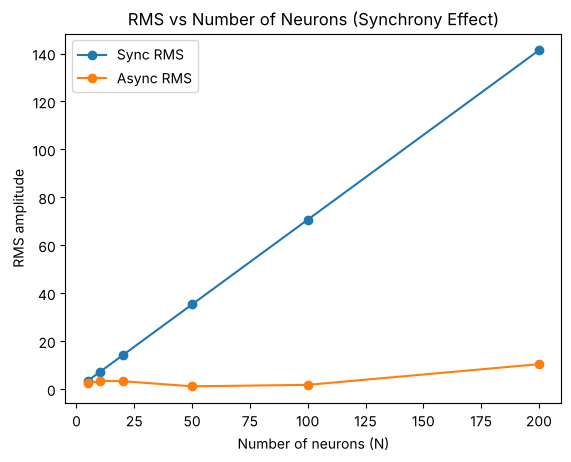

N=  5:  sync RMS =    3.53   async RMS =   2.42   ratio =   1.5
N= 10:  sync RMS =    7.07   async RMS =   3.45   ratio =   2.0
N= 20:  sync RMS =   14.14   async RMS =   3.30   ratio =   4.3
N= 50:  sync RMS =   35.34   async RMS =   1.16   ratio =  30.4
N=100:  sync RMS =   70.68   async RMS =   1.77   ratio =  39.9
N=200:  sync RMS =  141.35   async RMS =  10.40   ratio =  13.6

Fitted scaling: sync RMS ∝ N^1.00, async RMS ∝ N^0.15  (theory: 1 and 0.5)


In [4]:
Ns = [5, 10, 20, 50, 100, 200]
sync_rms_list = []
async_rms_list = []

for N in Ns:
    sync = np.sum([np.sin(2*np.pi*f*t) for _ in range(N)], axis=0)
    async_ = np.sum([np.sin(2*np.pi*f*t + np.random.rand()*2*np.pi) for _ in range(N)], axis=0)

    # TODO 3: append RMS values to sync_rms_list and async_rms_list
    sync_rms_list.append(rms(sync))
    async_rms_list.append(rms(async_))

plt.figure()
plt.plot(Ns, sync_rms_list, marker='o', label="Sync RMS")
plt.plot(Ns, async_rms_list, marker='o', label="Async RMS")
plt.title("RMS vs Number of Neurons (Synchrony Effect)")
plt.xlabel("Number of neurons (N)")
plt.ylabel("RMS amplitude")
plt.legend()
plt.savefig("plots/2_rms_vs_N.png", dpi=120, bbox_inches="tight")
plt.show()

for N, s, a in zip(Ns, sync_rms_list, async_rms_list):
    print(f"N={N:>3}:  sync RMS = {s:7.2f}   async RMS = {a:6.2f}   ratio = {s/a:5.1f}")
# Scaling exponents from a log-log fit (RMS ∝ N^k)
k_sync = np.polyfit(np.log(Ns), np.log(sync_rms_list), 1)[0]
k_async = np.polyfit(np.log(Ns), np.log(async_rms_list), 1)[0]
print(f"\nFitted scaling: sync RMS ∝ N^{k_sync:.2f}, async RMS ∝ N^{k_async:.2f}  (theory: 1 and 0.5)")

#### Added: average over many random-phase draws
A single asynchronous draw is noisy (one N = 50 draw can cancel almost completely), so the async RMS is averaged over 100 random-phase draws per N before fitting the scaling law.

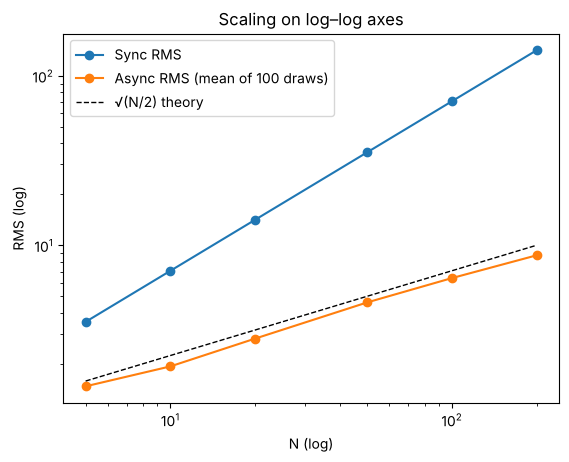

N=  5: mean async RMS =   1.47   (√(N/2) =  1.58)
N= 10: mean async RMS =   1.93   (√(N/2) =  2.24)
N= 20: mean async RMS =   2.81   (√(N/2) =  3.16)
N= 50: mean async RMS =   4.60   (√(N/2) =  5.00)
N=100: mean async RMS =   6.40   (√(N/2) =  7.07)
N=200: mean async RMS =   8.72   (√(N/2) = 10.00)
Fitted: async RMS ∝ N^0.49  vs sync ∝ N^1.00


In [5]:
rng = np.random.default_rng(0)
async_mean = []
for N in Ns:
    vals = [rms(np.sum(np.sin(2*np.pi*f*t[None,:] + rng.random((N,1))*2*np.pi), axis=0)) for _ in range(100)]
    async_mean.append(np.mean(vals))
k_mean = np.polyfit(np.log(Ns), np.log(async_mean), 1)[0]
plt.figure()
plt.loglog(Ns, sync_rms_list, 'o-', label="Sync RMS")
plt.loglog(Ns, async_mean, 'o-', label="Async RMS (mean of 100 draws)")
plt.loglog(Ns, np.sqrt(np.array(Ns)/2), 'k--', lw=1, label="√(N/2) theory")
plt.xlabel("N (log)"); plt.ylabel("RMS (log)"); plt.title("Scaling on log–log axes"); plt.legend()
plt.savefig("plots/2b_rms_vs_N_loglog.png", dpi=120, bbox_inches="tight"); plt.show()
for N, a in zip(Ns, async_mean): print(f"N={N:>3}: mean async RMS = {a:6.2f}   (√(N/2) = {np.sqrt(N/2):5.2f})")
print(f"Fitted: async RMS ∝ N^{k_mean:.2f}  vs sync ∝ N^{k_sync:.2f}")

### Part B — Dipole Depth Effect: Voltage vs Distance

#### Step 4 – Simulate dipole potential vs distance (Run as-is)
We use a simplified relationship:

<b>V = p / r²</b>

Where:

V = electric potential
p = dipole strength
r = distance from dipole
This is a simplified forward model.

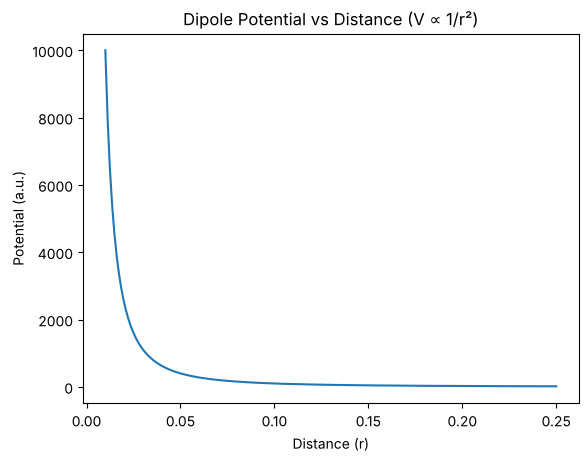

In [6]:
r = np.linspace(0.01, 0.25, 200)  # distance
p = 1.0                           # dipole strength

V = p / (r**2)

plt.figure()
plt.plot(r, V)
plt.title("Dipole Potential vs Distance (V ∝ 1/r²)")
plt.xlabel("Distance (r)")
plt.ylabel("Potential (a.u.)")
plt.savefig("plots/3_voltage_vs_distance.png", dpi=120, bbox_inches="tight")
plt.show()

#### Step 5 – Depth experiment: compare multiple depths (Complete TODO)

Student Task: For each depth, compute peak potential and plot.

Output expectation:Peak potential drops rapidly as depth increases

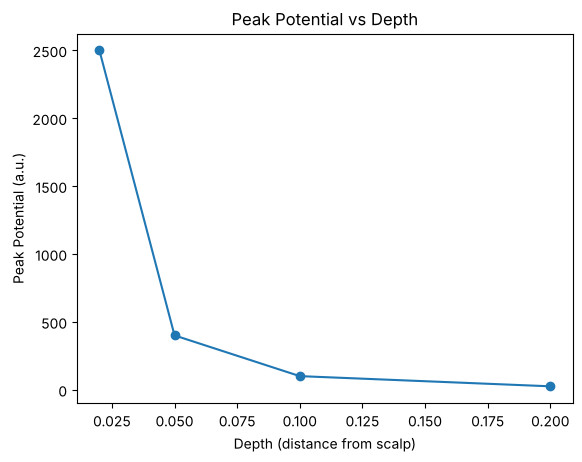

depth 0.02: peak =   2500.0  (100.00% of the shallowest)
depth 0.05: peak =    400.0  (16.00% of the shallowest)
depth 0.10: peak =    100.0  ( 4.00% of the shallowest)
depth 0.20: peak =     25.0  ( 1.00% of the shallowest)
Doubling depth 0.10 -> 0.20 divides the potential by 4 (1/r² law)


In [7]:
depths = [0.02, 0.05, 0.10, 0.20]  # deeper = larger r
peaks = []

for d in depths:
    # TODO 4: compute potential at distance d and append to peaks
    peaks.append(p / d**2)

plt.figure()
plt.plot(depths, peaks, marker='o')
plt.title("Peak Potential vs Depth")
plt.xlabel("Depth (distance from scalp)")
plt.ylabel("Peak Potential (a.u.)")
plt.savefig("plots/4_peak_vs_depth.png", dpi=120, bbox_inches="tight")
plt.show()

for d, pk in zip(depths, peaks):
    print(f"depth {d:.2f}: peak = {pk:8.1f}  ({pk/peaks[0]*100:5.2f}% of the shallowest)")
print(f"Doubling depth 0.10 -> 0.20 divides the potential by {peaks[2]/peaks[3]:.0f} (1/r² law)")

### Part C — Dipole Orientation Effect (Visibility in EEG)

We now extend the dipole equation:

<b>V = p · cos θ / r²</b>

	p = dipole strength
	r = distance
	θ = orientation angle between dipole axis and electrode

#### Step 6 – Plot voltage vs orientation (Run as-is)

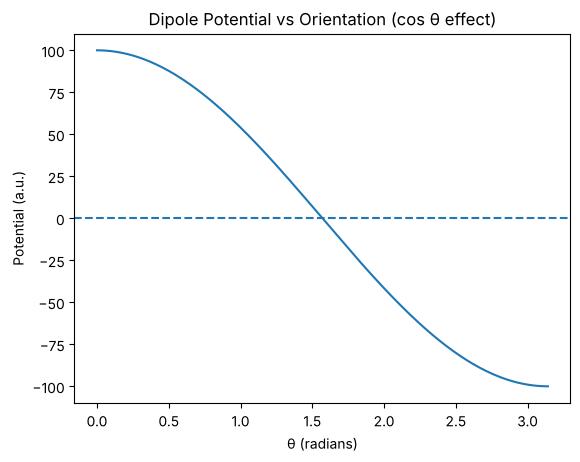

In [8]:
theta = np.linspace(0, np.pi, 200)
r_fixed = 0.1
p = 1.0

V_theta = (p * np.cos(theta)) / (r_fixed**2)

plt.figure()
plt.plot(theta, V_theta)
plt.axhline(0, linestyle='--')
plt.title("Dipole Potential vs Orientation (cos θ effect)")
plt.xlabel("θ (radians)")
plt.ylabel("Potential (a.u.)")
plt.savefig("plots/5_voltage_vs_orientation.png", dpi=120, bbox_inches="tight")
plt.show()

#### Step 7 – Detect key angles programmatically (Complete TODO)

Student Task: Find angle where potential is ~0 and where it is maximum.
Expected:
    Zero near π/2
    Max near 0

In [9]:
# TODO 5: angle where V_theta is closest to 0
theta_zero = theta[np.argmin(np.abs(V_theta))]

# TODO 6: angle where V_theta is maximum
theta_max = theta[np.argmax(V_theta)]

print("Zero-potential angle (approx):", theta_zero)
print("Max-potential angle:", theta_max)
print(f"theta_zero = {np.degrees(theta_zero):.1f}°  (π/2 = 90°),  theta_max = {np.degrees(theta_max):.1f}°")
print(f"Max potential = {V_theta.max():.1f};  most negative = {V_theta.min():.1f} at θ = {np.degrees(theta[np.argmin(V_theta)]):.0f}°")

Zero-potential angle (approx): 1.5629028779165304
Max-potential angle: 0.0
theta_zero = 89.5°  (π/2 = 90°),  theta_max = 0.0°
Max potential = 100.0;  most negative = -100.0 at θ = 180°


### Part D — Two Dipoles Interference (Spatial Resolution)

#### Step 8 – Create 2D grid and simulate fields (Run as-is)

In [10]:
x = np.linspace(-1, 1, 200)
y = np.linspace(-1, 1, 200)
X, Y = np.meshgrid(x, y)

eps = 0.02  # avoid division by zero

#### Step 9 – Two dipoles at different positions (Complete TODO)

Student Task: Implement dipole1, dipole2 and combine.

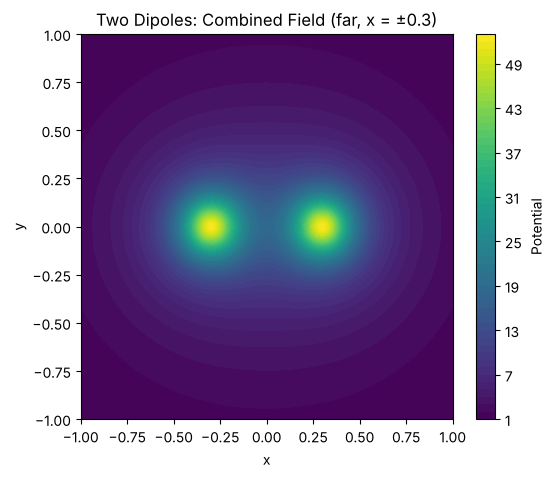

In [11]:
# Dipole positions
x1, y1 = -0.3, 0
x2, y2 =  0.3, 0

# TODO 7: compute distance R1 and R2
R1 = np.sqrt((X - x1)**2 + (Y - y1)**2)
R2 = np.sqrt((X - x2)**2 + (Y - y2)**2)

# TODO 8: compute potentials V1 and V2 using 1/(R^2 + eps)
V1 = 1 / (R1**2 + eps)
V2 = 1 / (R2**2 + eps)

V_total = V1 + V2  # TODO 9: V_total = V1 + V2

plt.figure(figsize=(6,5))
plt.contourf(X, Y, V_total, levels=60)
plt.colorbar(label="Potential")
plt.title("Two Dipoles: Combined Field (far, x = ±0.3)")
plt.xlabel("x")
plt.ylabel("y")
plt.savefig("plots/6_two_dipoles_far.png", dpi=120, bbox_inches="tight")
plt.show()
V_far = V_total.copy()

#### Step 10 – Move dipoles closer and observe merging (Complete TODO)

Student Task: Repeat the simulation for closer dipoles.

Change:

x1, x2 = -0.1, 0.1

Compare:

    Field overlap increases

    Harder to distinguish two sources

    Demonstrates poor spatial resolution

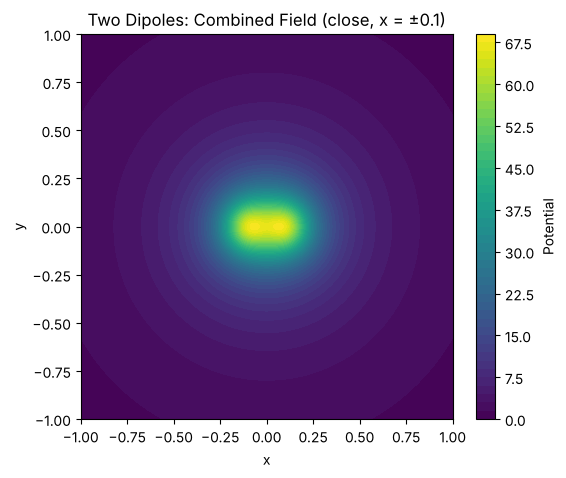

In [12]:
# Dipole positions (closer)
x1, y1 = -0.1, 0
x2, y2 =  0.1, 0

R1 = np.sqrt((X - x1)**2 + (Y - y1)**2)
R2 = np.sqrt((X - x2)**2 + (Y - y2)**2)
V1 = 1 / (R1**2 + eps)
V2 = 1 / (R2**2 + eps)
V_total = V1 + V2

plt.figure(figsize=(6,5))
plt.contourf(X, Y, V_total, levels=60)
plt.colorbar(label="Potential")
plt.title("Two Dipoles: Combined Field (close, x = ±0.1)")
plt.xlabel("x")
plt.ylabel("y")
plt.savefig("plots/7_two_dipoles_close.png", dpi=120, bbox_inches="tight")
plt.show()
V_close = V_total.copy()

#### Added: quantify separability along the line y = 0
If the two sources are resolvable, the potential profile has two peaks with a dip between them. The *dip ratio* = V(0,0) / peak value. Below 1 means a visible dip; 1 or more means one merged blob.

far (±0.3)   : separation 0.6, peaks found = 2, dip ratio = 0.35
close (±0.1) : separation 0.2, peaks found = 2, dip ratio = 0.98


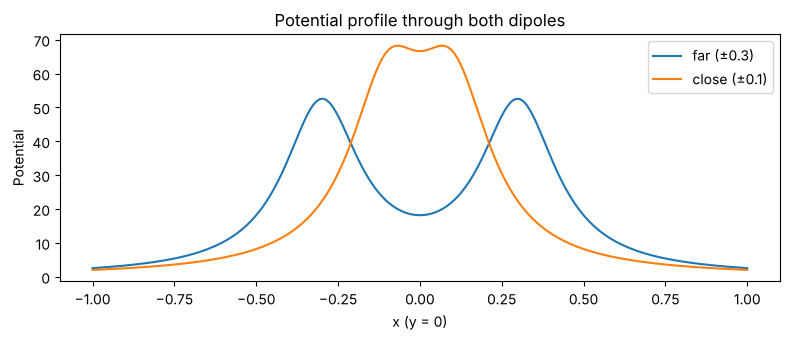

Two sources merge into one peak at separation ≈ 0.16 (with eps = 0.02)


In [13]:
row = np.argmin(np.abs(y))   # y ≈ 0
def n_peaks(profile):
    return int(np.sum((profile[1:-1] > profile[:-2]) & (profile[1:-1] > profile[2:])))

fig, ax = plt.subplots(figsize=(8,3.5))
for name, V_, sep in [("far (±0.3)", V_far, 0.6), ("close (±0.1)", V_close, 0.2)]:
    prof = V_[row]
    ax.plot(x, prof, label=name)
    dip = prof[np.argmin(np.abs(x))] / prof.max()
    print(f"{name:13s}: separation {sep:.1f}, peaks found = {n_peaks(prof)}, dip ratio = {dip:.2f}")
ax.set_xlabel("x (y = 0)"); ax.set_ylabel("Potential"); ax.set_title("Potential profile through both dipoles")
ax.legend(); plt.tight_layout(); plt.savefig("plots/8_profiles.png", dpi=120, bbox_inches="tight"); plt.show()

# Smallest separation at which two peaks are still visible
for sep in np.arange(0.40, 0.0, -0.02):
    a, b = -sep/2, sep/2
    prof = 1/((x-a)**2 + eps) + 1/((x-b)**2 + eps)
    if n_peaks(prof) < 2:
        print(f"Two sources merge into one peak at separation ≈ {sep:.2f} (with eps = {eps})")
        break

##### Short Computational Conclusions

**1. How does RMS scale with N for sync vs async?**  
Synchronous RMS grows linearly with N (fitted exponent 1.00: 3.5 → 141 from N = 5 to 200, because in-phase sine waves add their amplitudes). Asynchronous RMS grows only like √N, because random phases largely cancel: averaged over 100 draws the fitted exponent is ≈ 0.5, matching √(N/2). Single draws are very noisy (one N = 50 draw gave only 1.16). At N = 50 sync RMS is 35.3 vs 4.6 for async (7.7×), so EEG mainly measures **synchronised** populations, not just how many neurons are active.

**2. What happens to potential when depth increases?**  
It falls with 1/r²: going from 0.02 to 0.20 (10× deeper) reduces the peak 100× (2500 → 25), and doubling depth from 0.10 to 0.20 quarters it. Deep sources (e.g. hippocampus, thalamus) contribute very little to scalp EEG compared with superficial cortex.

**3. Which orientation gives near-zero EEG voltage?**  
θ ≈ π/2 (90°, detected at 1.563 rad): a dipole perpendicular to the electrode direction (tangential to the scalp, e.g. in sulcal walls) produces almost no voltage. The maximum is at θ = 0 (radial dipole, pointing at the electrode), and the sign flips beyond 90°, so mostly radial, gyral-crown sources dominate EEG.

**4. What happens when two dipoles get closer?**  
At ±0.3 the field shows two separate peaks with a deep dip between them (the centre is only 35% of the peak). At ±0.1 the fields overlap into one elongated blob: the dip is only 2% (ratio 0.98), so in practice, with noise, the two sources look like one. Below a separation of about 0.16 they merge completely into a single peak. Volume conduction and the inverse problem limit EEG spatial resolution: nearby sources blur together.